# TD-PINNs: Burgers Equation (1D & 2D)

Time-Decomposition PINNs for the viscous Burgers equation.  
A single `TD_PINNS` class handles both 1-D and 2-D — the PDE residual is
injected via `pde_loss_fn`, making it easy to plug in custom equations.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.join(os.path.abspath(''), '..'))

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.app import (
    TD_PINNS,
    TrainerBurger1D, TrainerBurger2D,
    Logger,
    plot_1d_evolution, plot_2d_evolution,
    plot_comparison_1d, plot_comparison_evolution,
    plot_error_evolution, plot_conservation,
    BurgersFD1D, build_comparison_table,
)

---
## 1-D Burgers Experiment

Toothsaw (sawtooth) analytic solution on $[0, 2\pi]$ with periodic boundary conditions.

In [2]:
# ── Analytic solution (Hopf-Cole transform) ────────────────────────────────

NU_1D = 0.07

def toothsaw(t=0, x=0):
    x  = np.asarray(x, dtype=float)
    nu = NU_1D
    a  = (-4*t + x)**2           / (4*nu*(t + 1))
    b  = (-4*t + x - 2*np.pi)**2 / (4*nu*(t + 1))
    num = ((-8*t + 2*x)            * np.exp(-a)
         + (-8*t + 2*x - 4*np.pi) * np.exp(-b)) / (4*nu*(t + 1))
    den = np.exp(-b) + np.exp(-a)
    return 2*nu * num / den + 4

In [3]:
# ── TD-PINN Setup ──────────────────────────────────────────────────────────

X0_1D, XF_1D = 0.0, 2 * np.pi
NX_1D = 100

trainer1d = TrainerBurger1D()
trainer1d.set_device('cpu')
trainer1d.set_simulation_parameters(
    nu=NU_1D, t0=0.0, dt=0.001, nt=10,
    x_bc=torch.Tensor([X0_1D, XF_1D]))
trainer1d.set_training_parameters(
    tol=1e-2, tol_ic=1e-2, max_epochs=80000, n_prints=10, lr=1e-2, min_lr=1e-8)
trainer1d.set_initial_condition(
    x_initial=torch.linspace(X0_1D, XF_1D, NX_1D), func=toothsaw)
trainer1d.set_boundary_function(toothsaw)

Using MPS


In [4]:
# ── Collocation strategies ─────────────────────────────────────────────────

def lhs_1d(x0, xf, n, device):
    cut = torch.linspace(0, 1, n + 1, device=device)
    u   = torch.rand(n, device=device)
    pts = cut[:-1] + (cut[1:] - cut[:-1]) * u
    return x0 + pts[torch.randperm(n, device=device)] * (xf - x0)

def collocation_uniform(PINN, t, res):
    return torch.linspace(X0_1D, XF_1D, NX_1D).to(trainer1d.device)

def collocation_lhs(PINN, t, res):
    return lhs_1d(X0_1D, XF_1D, NX_1D, trainer1d.device)

def collocation_gradient(PINN, t, res):
    n_a, n_u = NX_1D // 2, NX_1D // 2
    x_test   = torch.linspace(X0_1D, XF_1D, n_a * 3).reshape(-1, 1)
    du_dx, _ = PINN.grad(x_test)
    mag      = du_dx[:, 0].detach().abs()
    idx      = torch.argsort(mag / mag.sum(), descending=True)[:n_a]
    pts = torch.cat([x_test[idx].flatten().to(trainer1d.device),
                     torch.linspace(X0_1D, XF_1D, n_u).to(trainer1d.device)])
    return torch.sort(pts)[0]

def collocation_curvature(PINN, t, res):
    n_a, n_u  = NX_1D // 2, NX_1D // 2
    x_test    = torch.linspace(X0_1D, XF_1D, n_a * 3).reshape(-1, 1)
    _, du_dxx = PINN.grad(x_test)
    mag       = du_dxx[:, 0].detach().abs()
    idx       = torch.argsort(mag / mag.sum(), descending=True)[:n_a]
    pts = torch.cat([x_test[idx].flatten().to(trainer1d.device),
                     torch.linspace(X0_1D, XF_1D, n_u).to(trainer1d.device)])
    return torch.sort(pts)[0]

def collocation_residual(PINN, t, pde_res):
    if pde_res is None:
        return collocation_uniform(PINN, t, pde_res)
    n_a, n_u = NX_1D // 2, NX_1D // 2
    x_test   = torch.linspace(X0_1D, XF_1D, NX_1D).reshape(-1, 1)
    mag      = pde_res[:, 0].detach().abs()
    idx      = torch.argsort(mag / (mag.sum() + 1e-8), descending=True)[:n_a]
    pts = torch.cat([x_test[idx].flatten().to(trainer1d.device),
                     torch.linspace(X0_1D, XF_1D, n_u).to(trainer1d.device)])
    return torch.sort(pts)[0]

In [5]:
# Options: collocation_uniform, collocation_lhs,
#          collocation_gradient, collocation_curvature, collocation_residual
trainer1d.set_point_collocation_distribution(collocation_curvature)

t_pinn_start = time.perf_counter()
trainer1d.train_td_implicit()
t_pinn_total = time.perf_counter() - t_pinn_start
print(f"\nTotal PINN wall time: {t_pinn_total:.2f}s")

  Epoch      0: loss=435.839905  lr=1.00e-02
  Converged epoch=867  loss=0.009981

=== Step 1/9  t=0.0010 ===
  Epoch      0: loss=111.736786  lr=1.00e-02
  Epoch   8000: loss=0.609691  lr=1.25e-03
  Epoch  16000: loss=1.360532  lr=6.25e-04
  Epoch  24000: loss=0.020624  lr=3.13e-04
  Converged epoch=27026  loss=0.009981
  Done in 22.62s

=== Step 2/9  t=0.0020 ===
  Epoch      0: loss=105.174149  lr=1.00e-02
  Epoch   8000: loss=0.027652  lr=1.25e-03
  Converged epoch=12359  loss=0.010000
  Done in 10.37s

=== Step 3/9  t=0.0030 ===
  Epoch      0: loss=103.117310  lr=1.00e-02
  Epoch   8000: loss=0.641328  lr=1.91e-08
  Epoch  16000: loss=0.638444  lr=1.91e-08
  Epoch  24000: loss=0.612211  lr=1.91e-08
  Epoch  32000: loss=0.581298  lr=1.91e-08
  Epoch  40000: loss=0.551854  lr=1.91e-08
  Epoch  48000: loss=0.523931  lr=1.91e-08
  Epoch  56000: loss=0.497383  lr=1.91e-08
  Epoch  64000: loss=0.472201  lr=1.91e-08
  Epoch  72000: loss=0.448284  lr=1.91e-08
  Done in 66.78s

=== Step 4

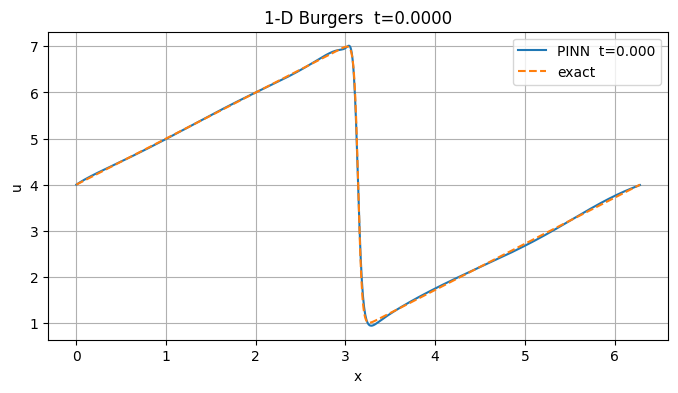

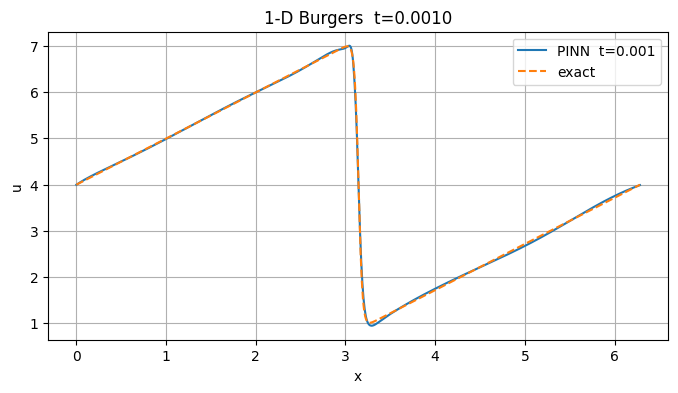

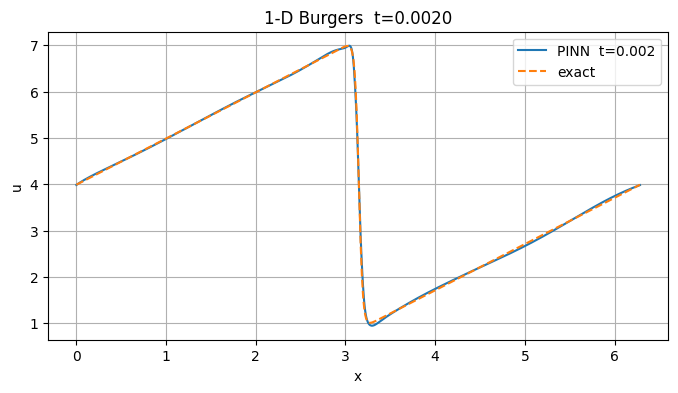

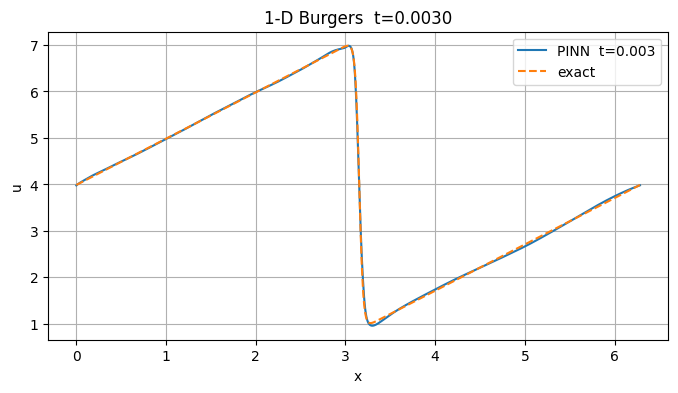

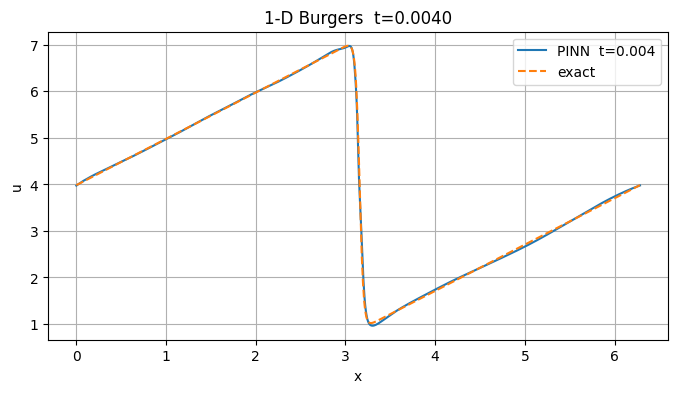

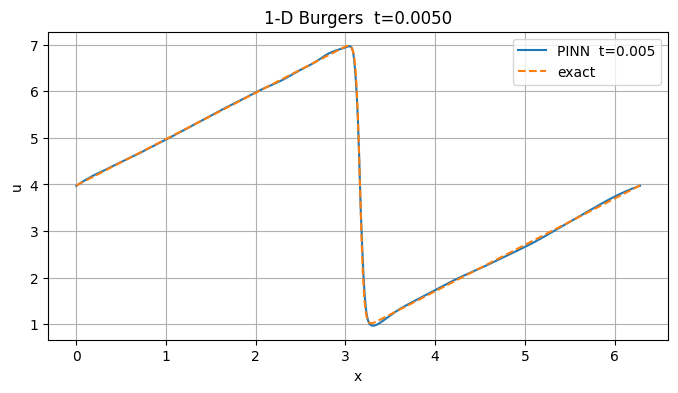

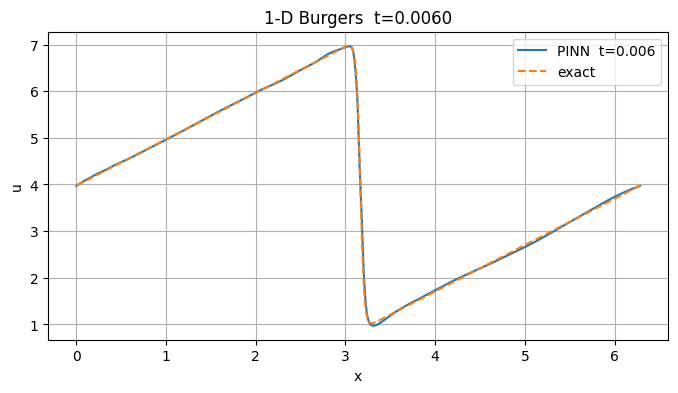

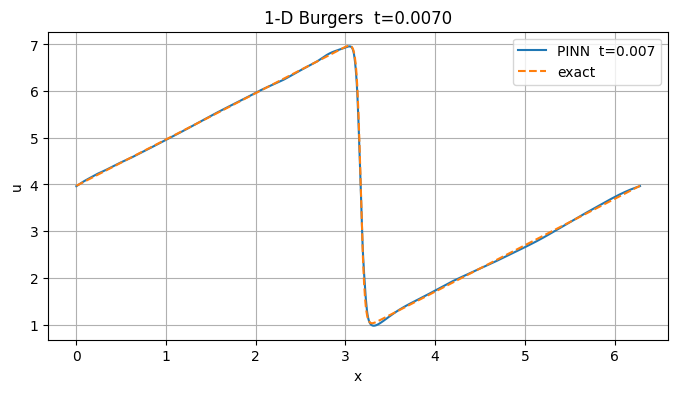

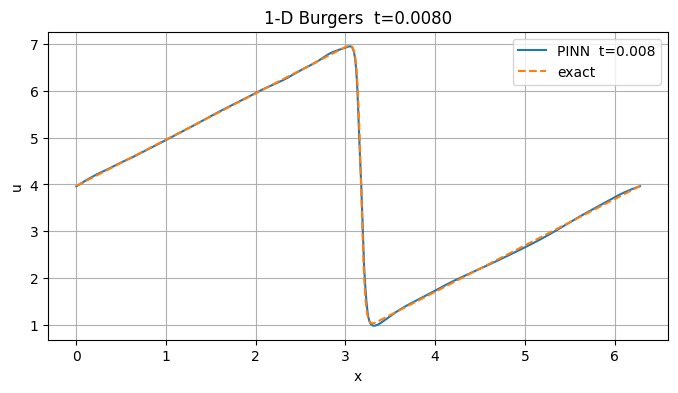

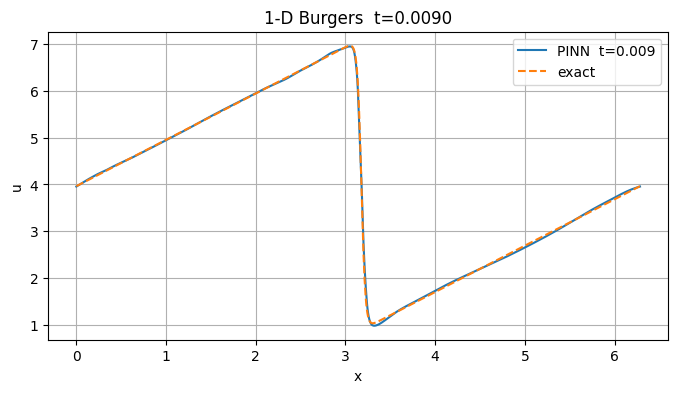

In [6]:
plot_1d_evolution(
    trainer1d.PINNS_list, trainer1d.t0, trainer1d.dt,
    X0_1D, XF_1D, trainer1d.device, analytic_func=toothsaw
)

---
## Comparison: TD-PINN vs Finite Differences (CFD Python Step 4)

**FD scheme** (Barba et al.):
$$
u_i^{n+1} = u_i^n
  - u_i^n \frac{\Delta t}{\Delta x}\left(u_i^n - u_{i-1}^n\right)
  + \nu \frac{\Delta t}{\Delta x^2}\left(u_{i+1}^n - 2u_i^n + u_{i-1}^n\right)
$$
Explicit upwind convection + central diffusion, periodic BCs.  
Stability: $\text{CFL} = |u|_{\max}\,\Delta t/\Delta x \le 1$,  $r = \nu\,\Delta t/\Delta x^2 \le 0.5$.

In [7]:
# ── Finite Difference solver ───────────────────────────────────────────────
NX_FD = 101      # grid points (matches CFD Python Step 4)
DT_FD = 0.001    # small enough for stability

solver_fd = BurgersFD1D(nu=NU_1D, x0=X0_1D, xf=XF_1D, nx=NX_FD, dt=DT_FD)
u0_fd     = toothsaw(t=trainer1d.t0, x=solver_fd.x)

stab = solver_fd.stability_report(u0_fd)
print("=== FD Stability Report ===")
for k, v in stab.items():
    print(f"  {k:<22} {v}")

=== FD Stability Report ===
  CFL                    0.111308
  CFL_limit              1.0
  CFL_ok                 True
  diffusion_r            0.017731
  diffusion_limit        0.5
  diffusion_ok           True
  scheme_stable          True
  dx                     0.062832
  dt                     0.001


In [8]:
# ── Run FD at the same time points as the PINN ────────────────────────────
t_compare = [trainer1d.t0 + i * trainer1d.dt for i in range(trainer1d.nt)]

t_fd_start = time.perf_counter()
fd_sols    = solver_fd.solve_at_times(u0_fd, [t for t in t_compare if t > 0])
t_fd_total = time.perf_counter() - t_fd_start
fd_sols[trainer1d.t0] = u0_fd

print(f"FD  wall time : {t_fd_total:.4f} s  ({len(t_compare)-1} outputs, "
      f"{round(trainer1d.dt / DT_FD):.0f} sub-steps each)")
print(f"PINN wall time: {t_pinn_total:.2f} s  ({trainer1d.nt} PINNs trained)")
print(f"Speed ratio   : {t_pinn_total / t_fd_total:.1f}x slower than FD")

FD  wall time : 0.0001 s  (9 outputs, 1 sub-steps each)
PINN wall time: 389.86 s  (10 PINNs trained)
Speed ratio   : 3089022.4x slower than FD


In [9]:
# ── Evaluate PINN on the FD grid (x_cmp) ──────────────────────────────────
x_cmp    = solver_fd.x
x_tensor = torch.as_tensor(x_cmp, dtype=torch.float32).reshape(-1, 1).to(trainer1d.device)

pinn_sols = {}
for i, P in enumerate(trainer1d.PINNS_list):
    t = trainer1d.t0 + i * trainer1d.dt
    with torch.no_grad():
        pinn_sols[t] = P.forward(x_tensor).cpu().numpy().ravel()

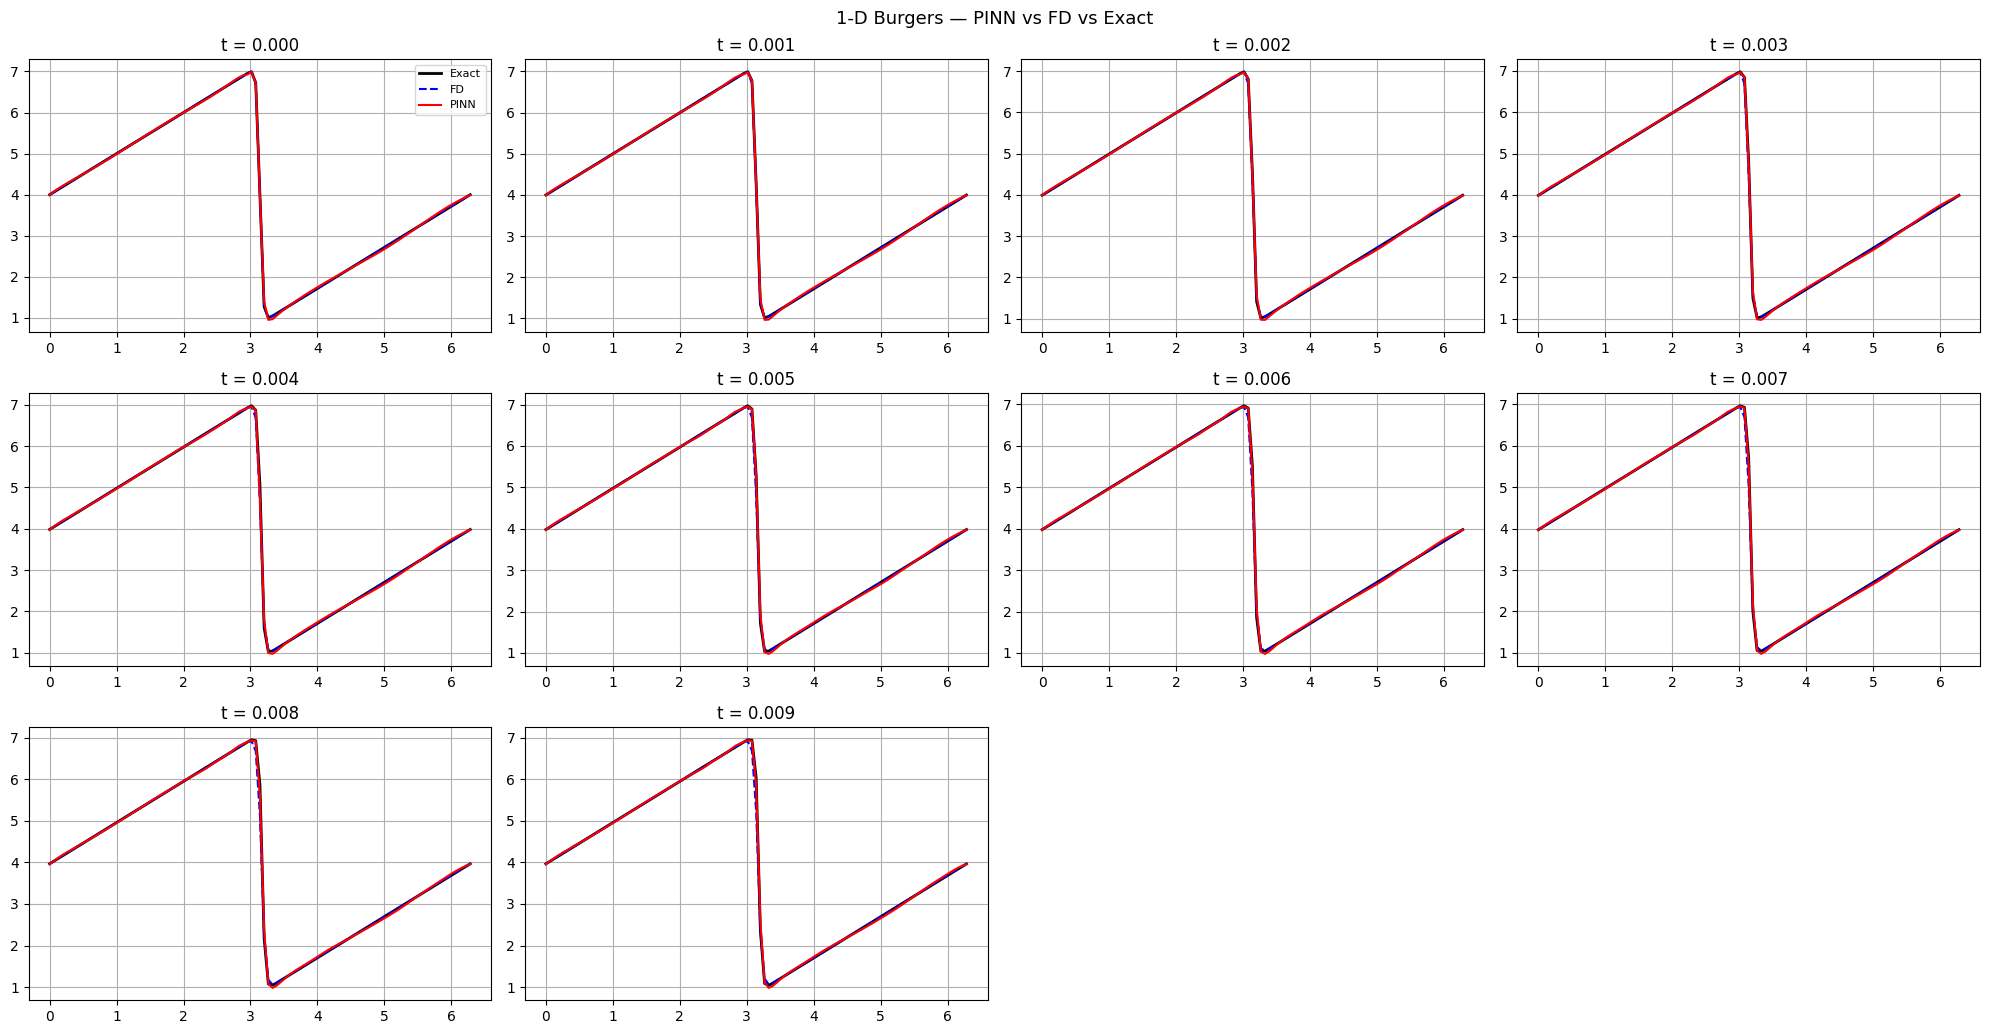

In [10]:
# ── Overlay comparison: all time steps in a grid ──────────────────────────
plot_comparison_evolution(t_compare, x_cmp, pinn_sols, fd_sols,
                          exact_func=toothsaw, ncols=4)

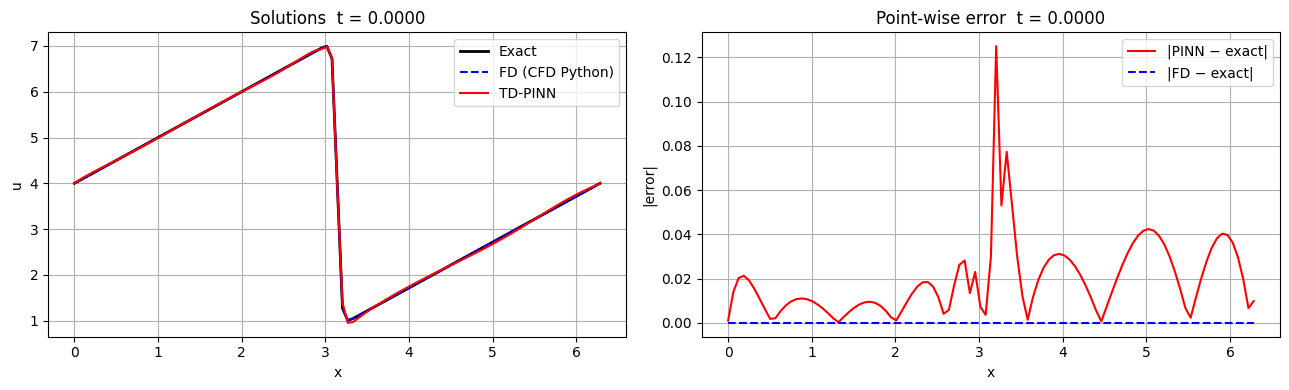

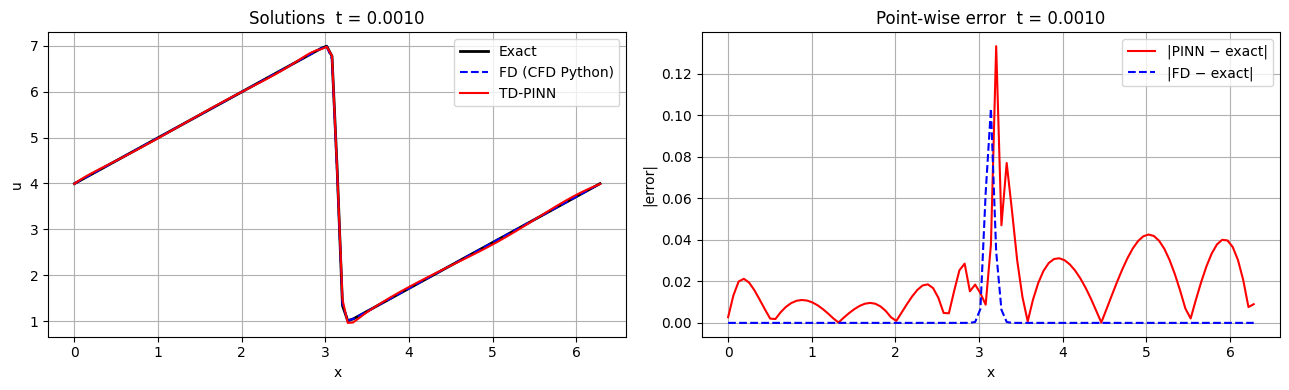

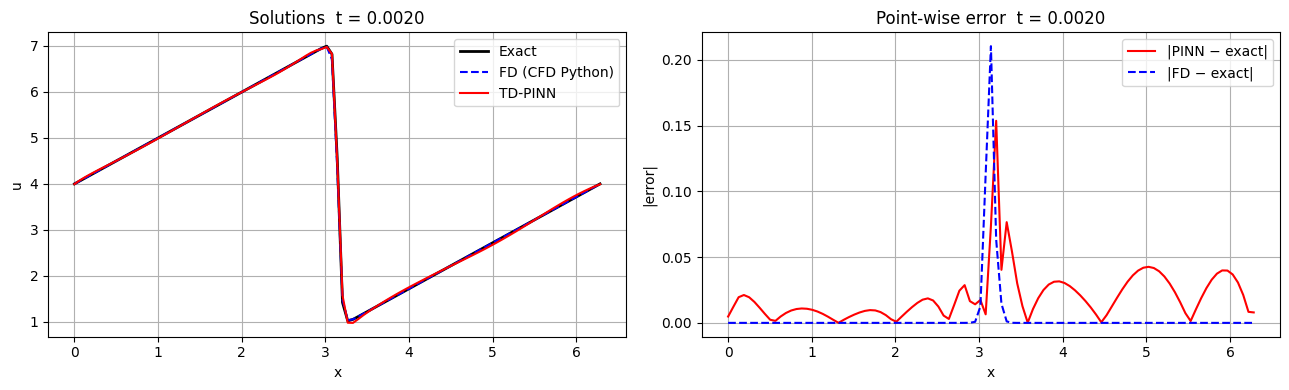

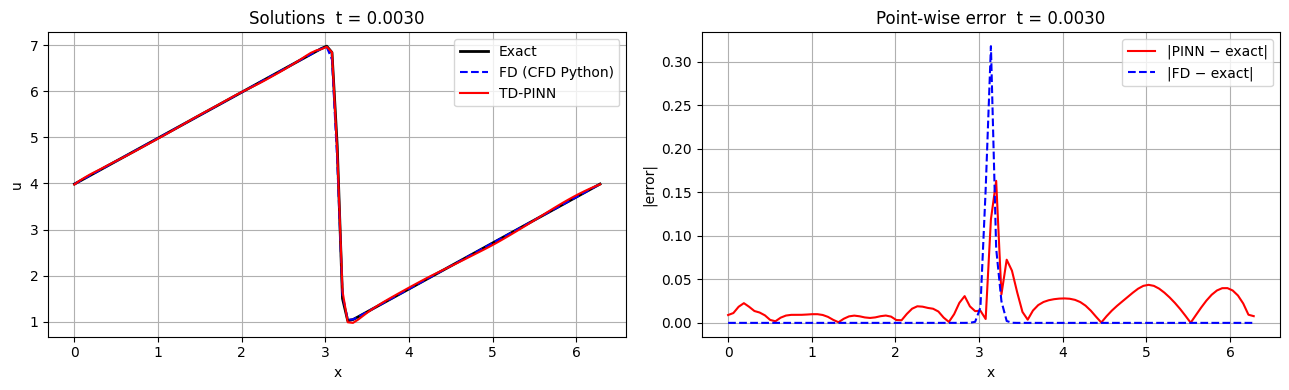

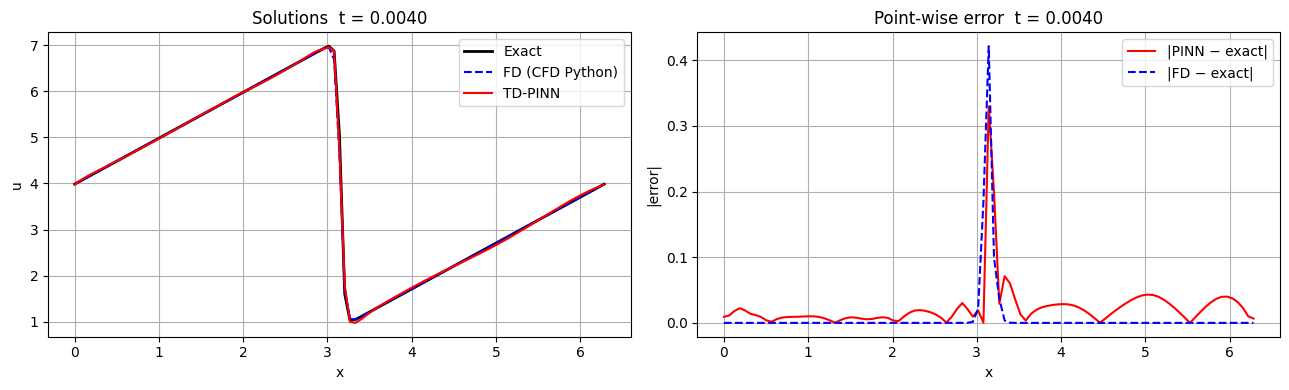

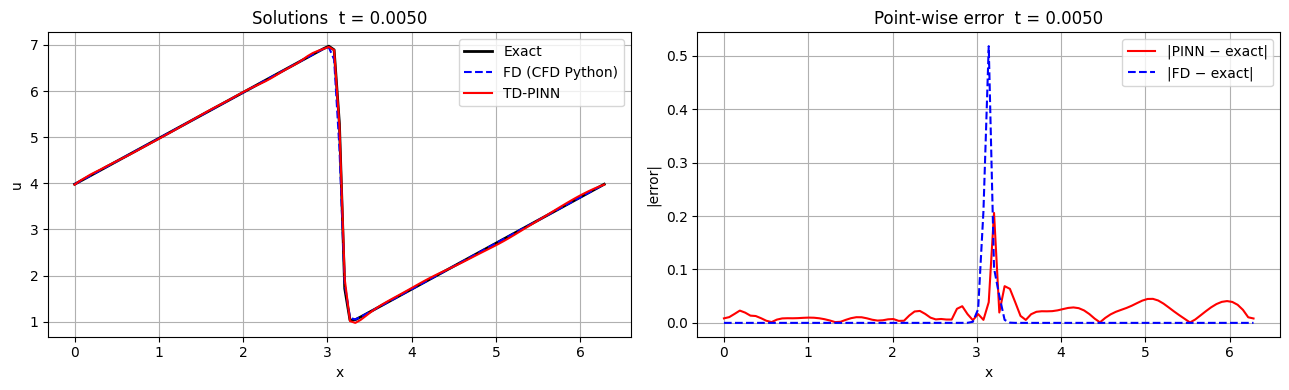

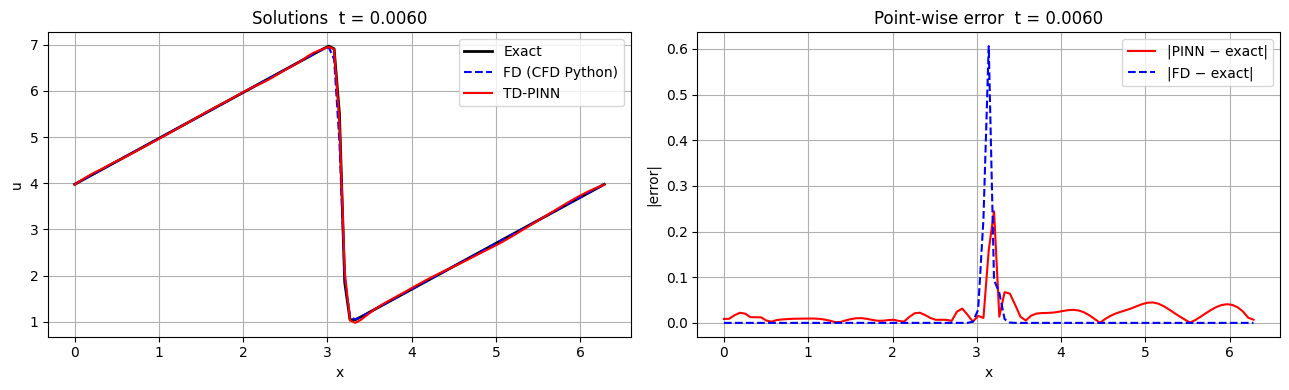

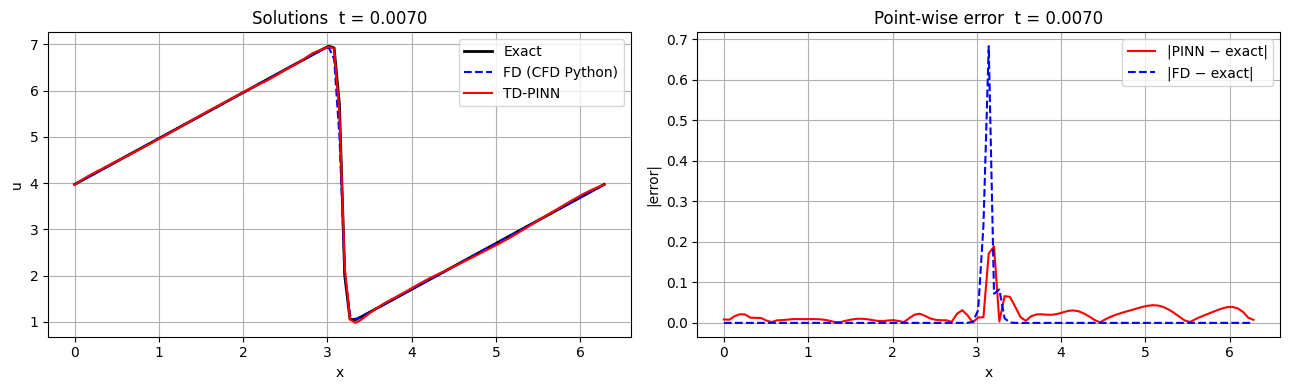

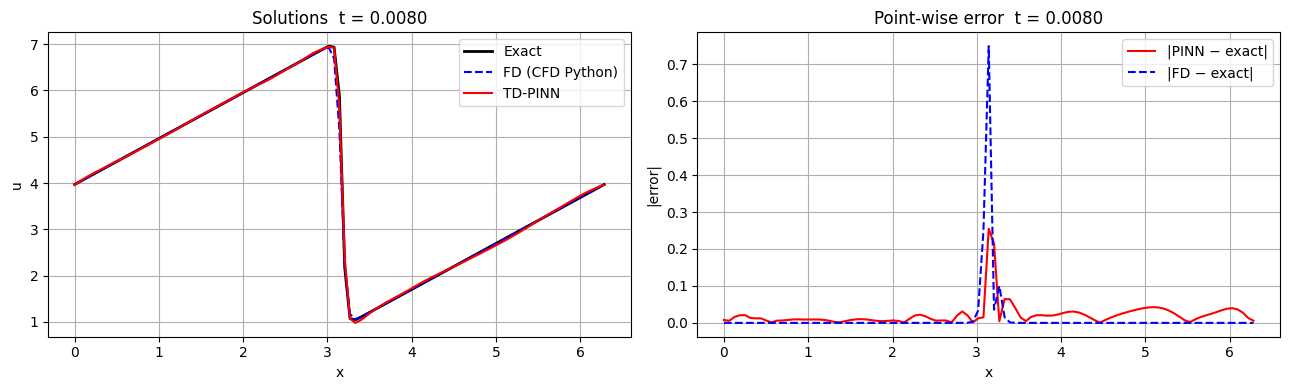

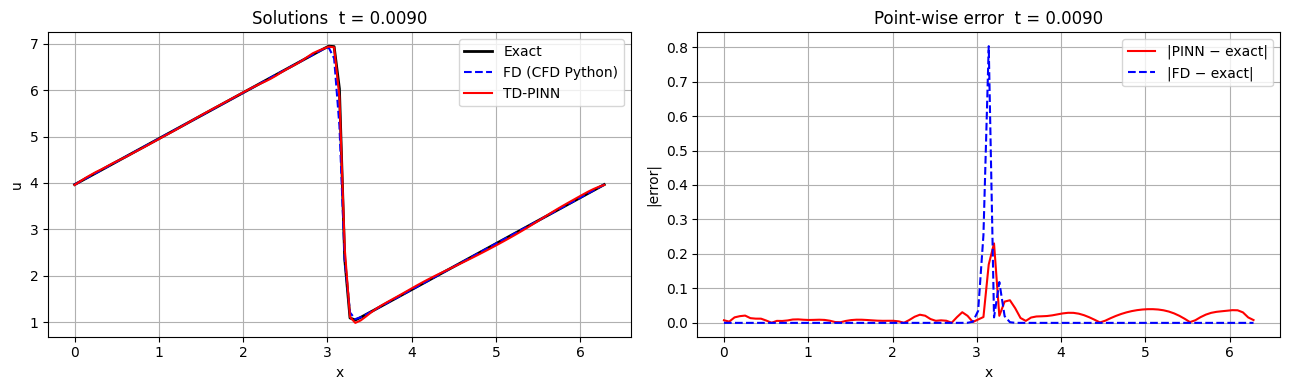

In [11]:
# ── Per-step overlay with point-wise error panel ──────────────────────────
for t in t_compare:
    plot_comparison_1d(t, x_cmp, pinn_sols[t], fd_sols[t],
                       u_exact=toothsaw(t=t, x=x_cmp))

In [12]:
# ── Numerical metrics table ────────────────────────────────────────────────
df = build_comparison_table(pinn_sols, fd_sols, toothsaw, t_compare, x_cmp)

pd.set_option('display.float_format', '{:.6f}'.format)
print("=== Per-time-step Error & Conservation Metrics ===\n")
print(df[['PINN_L2','FD_L2','PINN_Linf','FD_Linf',
          'PINN_rel_L2','FD_rel_L2']].to_string())

print("\n=== Summary ===")
summary = pd.DataFrame({
    'metric':     ['mean L2', 'max L2', 'mean Linf', 'max Linf',
                   'mean rel_L2', 'mass cons. max err', 'energy at t_final'],
    'PINN': [
        df['PINN_L2'].mean(),    df['PINN_L2'].max(),
        df['PINN_Linf'].mean(),  df['PINN_Linf'].max(),
        df['PINN_rel_L2'].mean(),
        (df['PINN_mass'] - df['exact_mass']).abs().max(),
        df['PINN_energy'].iloc[-1],
    ],
    'FD': [
        df['FD_L2'].mean(),      df['FD_L2'].max(),
        df['FD_Linf'].mean(),    df['FD_Linf'].max(),
        df['FD_rel_L2'].mean(),
        (df['FD_mass']   - df['exact_mass']).abs().max(),
        df['FD_energy'].iloc[-1],
    ],
}).set_index('metric')
print(summary.to_string())
df

=== Per-time-step Error & Conservation Metrics ===

          PINN_L2    FD_L2  PINN_Linf  FD_Linf  PINN_rel_L2  FD_rel_L2
t                                                                     
0.000000 0.026050 0.000000   0.125031 0.000000     0.005958   0.000000
0.001000 0.026405 0.012515   0.133169 0.103181     0.006040   0.002863
0.002000 0.028050 0.024665   0.153693 0.210464     0.006417   0.005643
0.003000 0.029977 0.036242   0.163081 0.317721     0.006859   0.008292
0.004000 0.044203 0.047019   0.329648 0.421275     0.010115   0.010760
0.005000 0.030335 0.056801   0.205866 0.518087     0.006943   0.013000
0.006000 0.036364 0.065455   0.244294 0.605845     0.008324   0.014983
0.007000 0.033391 0.072937   0.188987 0.682989     0.007645   0.016699
0.008000 0.039534 0.079303   0.254433 0.748662     0.009053   0.018160
0.009000 0.035780 0.084714   0.230441 0.802615     0.008195   0.019402

=== Summary ===
                        PINN        FD
metric                                
m

,PINN_L2,FD_L2,PINN_Linf,FD_Linf,PINN_rel_L2,FD_rel_L2,PINN_mass,FD_mass,exact_mass,PINN_energy,FD_energy,exact_energy
t,,,,,,,,,,,,
0.000000,0.026050,0.000000,0.125031,0.000000,0.005958,0.000000,25.135491,25.132741,25.132741,60.173307,60.155078,60.155078
0.001000,0.026405,0.012515,0.133169,0.103181,0.006040,0.002863,25.136568,25.125055,25.133363,60.156209,60.084534,60.138319
0.002000,0.028050,0.024665,0.153693,0.210464,0.006417,0.005643,25.136243,25.117630,25.133877,60.131370,60.016709,60.122784
0.003000,0.029977,0.036242,0.163081,0.317721,0.006859,0.008292,25.133983,25.110428,25.134206,60.101068,59.951155,60.107727
0.004000,0.044203,0.047019,0.329648,0.421275,0.010115,0.010760,25.122532,25.103424,25.134300,60.020589,59.887509,60.092350
0.005000,0.030335,0.056801,0.205866,0.518087,0.006943,0.013000,25.142217,25.096596,25.134149,60.101610,59.825490,60.075930
0.006000,0.036364,0.065455,0.244294,0.605845,0.008324,0.014983,25.136920,25.089931,25.133779,60.048178,59.764887,60.057932
0.007000,0.033391,0.072937,0.188987,0.682989,0.007645,0.016699,25.132350,25.083419,25.133252,60.016076,59.705547,60.038086
0.008000,0.039534,0.079303,0.254433,0.748662,0.009053,0.018160,25.128598,25.077055,25.132653,59.969273,59.647362,60.016426


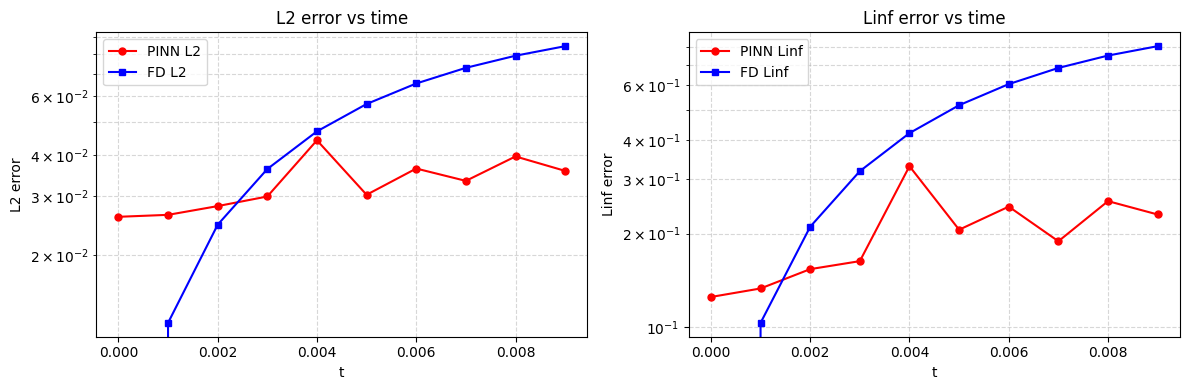

In [13]:
# ── Error evolution (semilogy) ─────────────────────────────────────────────
plot_error_evolution(t_compare, df, metrics=('L2', 'Linf'))

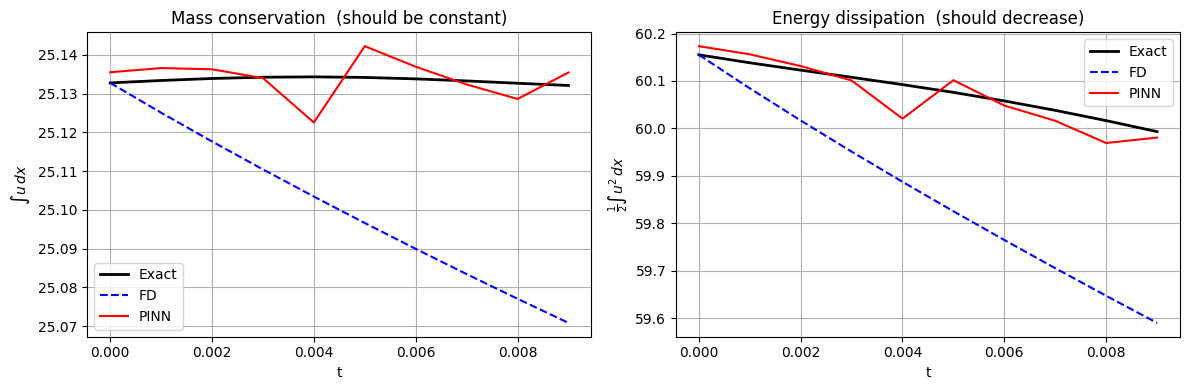

In [14]:
# ── Mass conservation & energy dissipation ─────────────────────────────────
plot_conservation(df)

---
## 2-D Burgers Experiment

Gaussian initial condition on $[-1,1]^2$ with zero Dirichlet boundary conditions.

In [15]:
# ── Initial / boundary conditions ──────────────────────────────────────────

def gaussian_ic(t=0, x=0, y=0):
    x, y = np.asarray(x), np.asarray(y)
    return np.exp(-(x**2 + y**2) / 0.1)

def zero_bc(t=0, x=0, y=0):
    return np.zeros_like(np.asarray(x))

In [16]:
# ── Setup ──────────────────────────────────────────────────────────────────

NU_2D = 0.01
X0_2D, XF_2D = -1.0, 1.0
Y0_2D, YF_2D = -1.0, 1.0
NX_2D, NY_2D = 20, 20

trainer2d = TrainerBurger2D()
trainer2d.set_device('cpu')
trainer2d.set_simulation_parameters(
    nu=NU_2D, t0=0.0, dt=0.2, nt=6,
    x_range=(X0_2D, XF_2D), y_range=(Y0_2D, YF_2D))
trainer2d.set_training_parameters(
    tol=1e-2, tol_ic=1e-2, max_epochs=30000, n_prints=10, lr=1e-2, min_lr=1e-8)

xy0 = trainer2d.create_2d_grid(NX_2D, NY_2D)
trainer2d.set_initial_condition(xy_initial=xy0, func=gaussian_ic)
trainer2d.set_boundary_function(zero_bc)

Using MPS


In [17]:
# ── Collocation strategies ─────────────────────────────────────────────────

def lhs_2d(x_range, y_range, n, device):
    cut = torch.linspace(0, 1, n + 1, device=device)
    u   = torch.rand(n, 2, device=device)
    a, b = cut[:-1], cut[1:]
    s = a.unsqueeze(1) + (b - a).unsqueeze(1) * u
    for j in range(2):
        s[:, j] = s[torch.randperm(n, device=device), j]
    xmn, xmx = x_range; ymn, ymx = y_range
    s[:, 0] = xmn + s[:, 0] * (xmx - xmn)
    s[:, 1] = ymn + s[:, 1] * (ymx - ymn)
    return s

def collocation_2d_uniform(PINN, t, res):
    return trainer2d.create_2d_grid(NX_2D, NY_2D)

def collocation_2d_lhs(PINN, t, res):
    return lhs_2d((X0_2D, XF_2D), (Y0_2D, YF_2D), NX_2D * NY_2D, trainer2d.device)

def collocation_2d_gradient(PINN, t, res):
    m, n_a = 2, NX_2D * NY_2D // 2
    xy     = trainer2d.create_2d_grid(NX_2D * m, NY_2D * m)
    g, _   = PINN.grad(xy)
    mag    = torch.sqrt(g[:, 0]**2 + g[:, 1]**2).detach()
    idx    = torch.argsort(mag, descending=True)[:n_a]
    n_u    = int(np.sqrt(NX_2D * NY_2D - n_a))
    return torch.cat([xy[idx].detach(),
                      trainer2d.create_2d_grid(n_u, n_u)]).to(trainer2d.device)

def collocation_2d_residual(PINN, t, pde_res):
    if pde_res is None:
        return collocation_2d_uniform(PINN, t, pde_res)
    n_a = NX_2D * NY_2D // 2
    xy  = trainer2d.create_2d_grid(NX_2D, NY_2D)
    mag = pde_res[:, 0].detach().abs()
    idx = torch.argsort(mag / (mag.sum() + 1e-8), descending=True)[:n_a]
    n_u = int(np.sqrt(NX_2D * NY_2D - n_a))
    return torch.cat([xy[idx].detach(),
                      trainer2d.create_2d_grid(n_u, n_u)]).to(trainer2d.device)

In [18]:
# Options: collocation_2d_uniform, collocation_2d_lhs,
#          collocation_2d_gradient, collocation_2d_residual
trainer2d.set_point_collocation_distribution(collocation_2d_uniform)
trainer2d.train_td_implicit()

  Epoch      0: loss=0.972312  lr=1.00e-02
  Converged epoch=400  loss=0.009983

=== Step 1/5  t=0.2000 ===
  Epoch      0: loss=0.013350  lr=1.00e-02
  Converged epoch=76  loss=0.009952
  Done in 0.17s

=== Step 2/5  t=0.4000 ===
  Converged epoch=0  loss=0.002750
  Done in 0.00s

=== Step 3/5  t=0.6000 ===
  Converged epoch=0  loss=0.002750
  Done in 0.00s

=== Step 4/5  t=0.8000 ===
  Converged epoch=0  loss=0.002750
  Done in 0.00s

=== Step 5/5  t=1.0000 ===
  Converged epoch=0  loss=0.002750
  Done in 0.00s


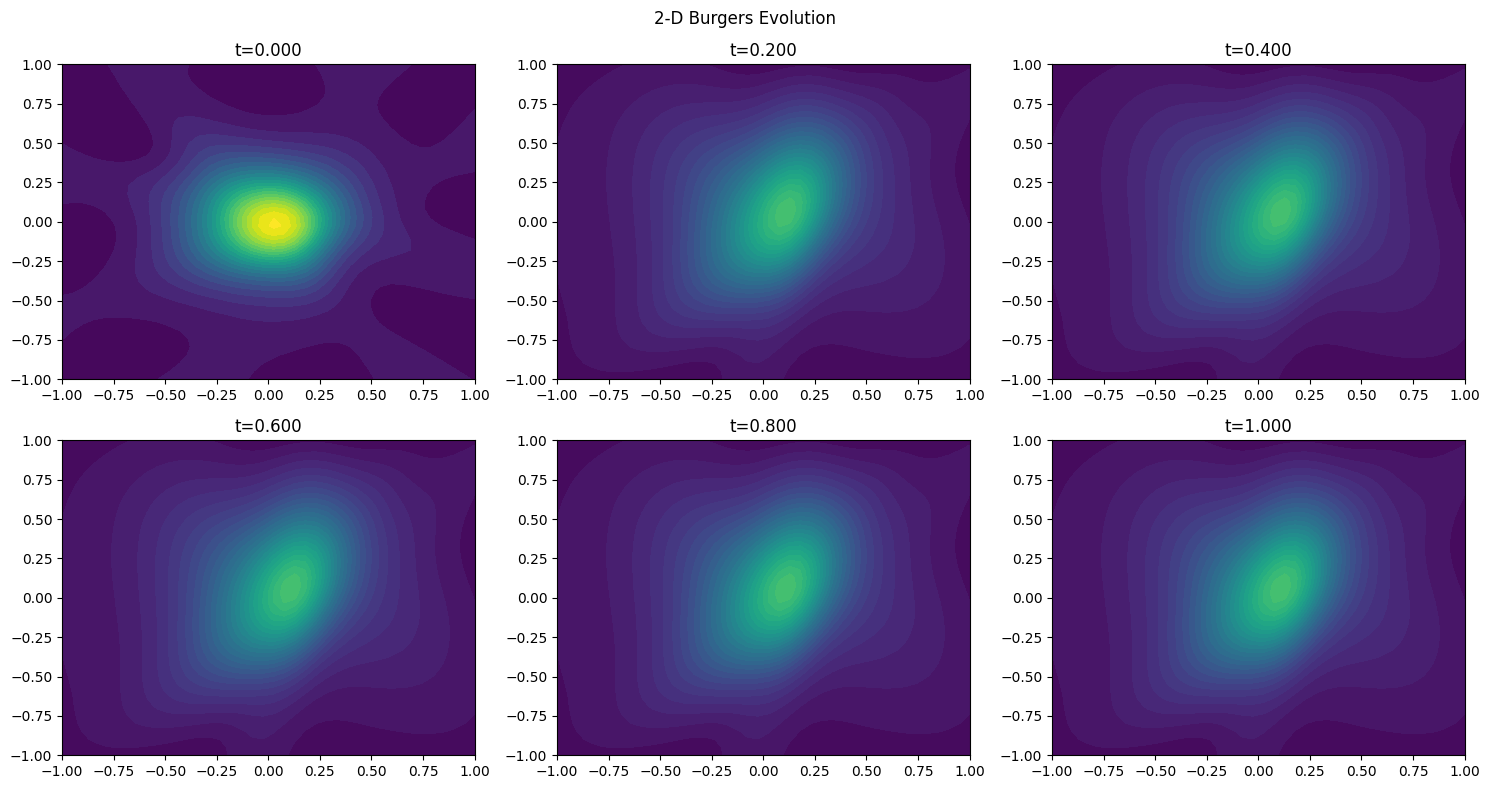

In [19]:
plot_2d_evolution(
    trainer2d.PINNS_list, trainer2d.t0, trainer2d.dt,
    (X0_2D, XF_2D), (Y0_2D, YF_2D), trainer2d.device,
    nx=40, ny=40, ncols=3
)

In [21]:
a =int(input())
(1, 2, 3, 4)[a if a%2 == 0 else 0]

ValueError: invalid literal for int() with base 10: ''